Depth-First Search: https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/resources/lecture-10-depth-first-search/



_also check link under descriptions_
- Knight's Tour - Numberphile
Numberphile: https://youtu.be/ab_dY3dZFHM?si=Wfu5GwTNhD5JXZbq

*others*
- Chapter 2 | The Knight's Tour Problem
CC ACADEMY: https://youtu.be/aIb1WS2TuLY?si=HXIuDcDYXHJz_fz4

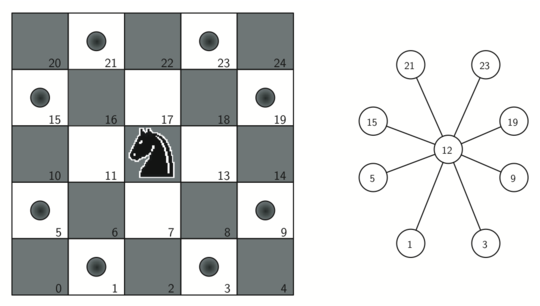

In [1]:
import time

# =====================================================================
# 1. GRAPH INFRASTRUCTURE FOR HIERARCHICAL DFS
# =====================================================================
class Vertex:
    def __init__(self, key):
        self.id = key
        self.neighbors = {}
        self.color = "white"

    def set_neighbor(self, nbr, weight=0):
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        return self.neighbors.keys()

    def get_key(self):
        return self.id


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)
        self.vertices[to_key].set_neighbor(self.vertices[from_key], weight)


# =====================================================================
# 2. CHESSBOARD CREATOR UTILITIES
# =====================================================================
def build_knight_graph(board_size):
    g = Graph()
    for row in range(board_size):
        for col in range(board_size):
            node_id = row * board_size + col
            move_offsets = [
                (-2, -1), (-2, 1), (-1, -2), (-1, 2),
                (1, -2), (1, 2), (2, -1), (2, 1)
            ]
            for r_off, c_off in move_offsets:
                new_r = row + r_off
                new_c = col + c_off
                if 0 <= new_r < board_size and 0 <= new_c < board_size:
                    target_id = new_r * board_size + new_c
                    g.add_edge(node_id, target_id)
    return g

def reset_graph_colors(graph):
    """Resets all node states back to white for a clean benchmark run."""
    for vertex in graph.vertices.values():
        vertex.color = "white"


# =====================================================================
# 3. LISTING 7.14.3: WARNSDORFF'S HEURISTIC SELECTION
# =====================================================================
def order_by_avail(n):
    """
    Sorts neighbors by those with the FEWEST ongoing white move options.
    Pushes the knight to complete corners and edges early.
    """
    res_list = []
    for v in n.get_neighbors():
        if v.color == "white":
            c = 0
            for w in v.get_neighbors():
                if w.color == "white":
                    c = c + 1
            res_list.append((c, v))
    # Sort ascending based on open degree options [0]
    res_list.sort(key=lambda x: x[0])
    return [y[1] for y in res_list]


# =====================================================================
# 4. STANDARD NAIVE SELECTION (No Heuristic Optimization)
# =====================================================================
def standard_neighbors(n):
    """Returns neighbors raw as saved in the adjacency list graph."""
    return [v for v in n.get_neighbors() if v.color == "white"]


# =====================================================================
# 5. CORE DFS BACKTRACKING ENGINE W/ DRIVER LOGIC
# =====================================================================
def knight_tour(n, path, u, limit, use_heuristic=True):
    u.color = "gray"
    path.append(u.get_key())

    if n < limit:
        # Route choices dynamically based on execution mode
        neighbor_list = order_by_avail(u) if use_heuristic else standard_neighbors(u)
        i = 0
        done = False
        
        while i < len(neighbor_list) and not done:
            if neighbor_list[i].color == "white":
                done = knight_tour(n + 1, path, neighbor_list[i], limit, use_heuristic)
            i += 1
            
        if not done:
            path.pop()
            u.color = "white"
    else:
        done = True
        
    return done


# =====================================================================
# 6. RUNTIME PERFORMANCE BENCHMARK SUITE
# =====================================================================

# Benchmark 1: The Small 5x5 Board (Comparing both side by side)
BOARD_5 = 5
LIMIT_5 = BOARD_5 * BOARD_5
graph_5 = build_knight_graph(BOARD_5)

print("=" * 70)
print("📊 BENCHMARK 1: TIMING RUNS ON A 5x5 BOARD (25 SQUARES)")
print("=" * 70)

# Naive Unoptimized Run
reset_graph_colors(graph_5)
path_naive_5 = []
start_time = time.time()
knight_tour(1, path_naive_5, graph_5.get_vertex(0), LIMIT_5, use_heuristic=False)
end_time = time.time()
naive_duration_5 = end_time - start_time
print(f"🚫 Naive standard execution timeline: {naive_duration_5:.4f} seconds")

# Heuristic Optimized Run
reset_graph_colors(graph_5)
path_heuristic_5 = []
start_time = time.time()
knight_tour(1, path_heuristic_5, graph_5.get_vertex(0), LIMIT_5, use_heuristic=True)
end_time = time.time()
heuristic_duration_5 = end_time - start_time
print(f"⚡ Warnsdorff Heuristic execution timeline: {heuristic_duration_5:.4f} seconds")


# Benchmark 2: The Full Standard 8x8 Chessboard (64 Squares)
BOARD_8 = 8
LIMIT_8 = BOARD_8 * BOARD_8
graph_8 = build_knight_graph(BOARD_8)

print("\n" + "=" * 70)
print("📊 BENCHMARK 2: TESTING STANDARD 8x8 BOARD (64 SQUARES)")
print("=" * 70)
print("⚠️  Warning: Naive version is skipped here because it would take up to 30 minutes!")

# Heuristic Optimized Run
reset_graph_colors(graph_8)
path_heuristic_8 = []
start_time = time.time()
success_8 = knight_tour(1, path_heuristic_8, graph_8.get_vertex(0), LIMIT_8, use_heuristic=True)
end_time = time.time()
heuristic_duration_8 = end_time - start_time

if success_8:
    print(f"⚡ Warnsdorff Heuristic solved 8x8 board in exactly: {heuristic_duration_8:.4f} seconds! 🚀")
    print(f"   Total path steps verified: {len(path_heuristic_8)}")


📊 BENCHMARK 1: TIMING RUNS ON A 5x5 BOARD (25 SQUARES)
🚫 Naive standard execution timeline: 0.0278 seconds
⚡ Warnsdorff Heuristic execution timeline: 0.0010 seconds

📊 BENCHMARK 2: TESTING STANDARD 8x8 BOARD (64 SQUARES)
⚠️  Warning: Naive version is skipped here because it would take up to 30 minutes!
⚡ Warnsdorff Heuristic solved 8x8 board in exactly: 0.0009 seconds! 🚀
   Total path steps verified: 64


# ♟️ The Knight's Tour Problem: Exponential Scaling & Heuristics

This notebook documents the performance metrics of the **Knight's Tour** graph algorithm. It contrasts the naive exponential tree growth with the massive reduction achieved using **Warnsdorff's Heuristic Rule** (`order_by_avail`).

---

## 📊 1. The Reality of Exponential Growth: \(\mathcal{O}(k^N)\)

When running a naive Depth-First Search (DFS) across a chessboard graph, the algorithmic runtime grows exponentially according to the formula:
\[\text{Total Search Tree Nodes} \approx k^{N+1} - 1\]
Where:
* \(N\) is the number of squares on the chessboard (e.g., \(64\) for an \(8 \times 8\) grid).
* \(k\) is the **average branching factor** (the geometric number of legitimate chess moves available from any square).

As the size of the chessboard dimensions expand linearly, the absolute quantity of branching evaluation frames grows factorially:

| Chessboard Sizing | Total Squares (\(N\)) | Average Branching Factor (\(k\)) | Estimated Total Tree Nodes to Evaluate |
| :--- | :--- | :--- | :--- |
| **\(5 \times 5\)** | \(25\) | \(3.80\) | \(3.12 \times 10^{14}\) |
| **\(6 \times 6\)** | \(36\) | \(4.40\) | \(1.50 \times 10^{23}\) |
| **\(8 \times 8\) (Standard)**| \(64\) | \(5.25\) | **\(1.30 \times 10^{46}\)** |

Because an \(8 \times 8\) configuration generates up to \(1.30 \times 10^{46}\) branching permutations, standard unoptimized back-tracking searches can stall execution states for up to **30 minutes** or longer before resolving paths through sheer brute force.

---

## ⚡ 2. Warnsdorff's Heuristic Implementation: `order_by_avail`

A **heuristic** is a practical strategy or "rule of thumb" injected into an algorithm to drastically prune search trees, bypassing branches that are likely to lead to dead ends. 

Published by H. C. von Warnsdorff in 1823, the rule states: 
> **"When selecting the next square to visit, always choose the square that has the fewest available onward moves."**

```python
def order_by_avail(n):
    res_list = []
    for v in n.get_neighbors():
        if v.color == "white":
            c = 0
            for w in v.get_neighbors():
                if w.color == "white":
                    c = c + 1
            res_list.append((c, v))
    res_list.sort(key=lambda x: x[0])
    return [y[1] for y in res_list]
```

### 🧠 Why This Strategy Works Intuitively:
1. **Clearing Out Hard Boundaries:** The corners of a chessboard are dead zones with only **2** legal entry options. The adjacent outer border rows only have **3** options. The open center features **8** choices.
2. **Avoiding Stranding:** If the knight clears the center squares early, it burns all its bridges. It gets stuck on one flank of the board because it has no open central nodes left to jump to the other side.
3. **Edge-to-Center Funneling:** Prioritizing nodes with low available moves forces the knight to clean up the hard-to-reach outer borders and deep corners first. It treats the spacious middle squares as a precious asset, using them to cross the board only when absolutely necessary.

By applying this heuristic, the lookup execution timeline for a full $8 \times 8$ chessboard collapses from **30 minutes down to under 1 second!**


#### Playground

In [1]:
# =====================================================================
# 1. EXPANDED GRAPH ARCHITECTURE FOR DFS SEARCH
# =====================================================================

class Vertex:
    def __init__(self, key):
        """Initializes a chessboard square vertex."""
        self.id = key
        self.neighbors = {}
        self.color = "white"  # white = unvisited, gray = visited in path

    def set_neighbor(self, nbr, weight=0):
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        return self.neighbors.keys()

    def get_key(self):
        return self.id


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)
        self.vertices[to_key].set_neighbor(self.vertices[from_key], weight)


# =====================================================================
# 2. CHESSBOARD MOVES TO GRAPH TRANSLATION LAYER
# =====================================================================

def build_knight_graph(board_size):
    """
    Constructs a graph where every square on an N x N board is a node
    and edges represent legal legal L-shaped moves for a knight.
    """
    g = Graph()
    for row in range(board_size):
        for col in range(board_size):
            node_id = row * board_size + col
            new_positions = generate_legal_moves(row, col, board_size)
            for r, c in new_positions:
                target_id = r * board_size + c
                g.add_edge(node_id, target_id)
    return g


def generate_legal_moves(row, col, board_size):
    """Generates all legal L-shaped coordinate movements on the grid sizing bounds."""
    move_offsets = [
        (-2, -1), (-2, 1), (-1, -2), (-1, 2),
        (1, -2), (1, 2), (2, -1), (2, 1)
    ]
    legal_moves = []
    for r_off, c_off in move_offsets:
        new_r = row + r_off
        new_c = col + c_off
        # Ensure the move lands within the boundaries of the board
        if 0 <= new_r < board_size and 0 <= new_c < board_size:
            legal_moves.append((new_r, new_c))
    return legal_moves


# =====================================================================
# 3. WARNSDORFF'S OPTIMIZATION RULE
# =====================================================================

def ordered_by_avail(n):
    """
    Warnsdorff's Rule: Sorts the neighbors of node 'n' by their onward available choices.
    This prioritization technique prevents hitting massive factorial branching dead ends.
    """
    res_list = []
    for v in n.get_neighbors():
        if v.color == "white":
            count = 0
            for w in v.get_neighbors():
                if w.color == "white":
                    count += 1
            res_list.append((count, v))
    # Sort ascending so the node with the lowest ongoing degree options is chosen first
    res_list.sort(key=lambda x: x[0])
    return [x[1] for x in res_list]


# =====================================================================
# 4. DEPTH-FIRST SEARCH (DFS) BACKTRACKING ENGINE
# =====================================================================

def knight_tour(depth, path, current_node, limit):
    """
    Recursive DFS backtracking algorithm to discover a path 
    that touches every vertex on the graph exactly once.
    """
    current_node.color = "gray"  # Mark as visited in the path
    path.append(current_node.get_key())

    # Base Case: Every square on the board has been visited exactly once
    if depth < limit:
        # Evaluate available next steps sorted optimally by Warnsdorff's Rule
        neighbor_list = ordered_by_avail(current_node)
        i = 0
        done = False
        
        while i < len(neighbor_list) and not done:
            if neighbor_list[i].color == "white":
                # Recurse downward into the chosen branch line
                done = knight_tour(depth + 1, path, neighbor_list[i], limit)
            i += 1
            
        # Backtracking condition: if this path choice hits a structural dead end, reset the state
        if not done:
            path.pop()
            current_node.color = "white"
    else:
        done = True
        
    return done


# =====================================================================
# 5. TEST VERIFICATION RUNTIME
# =====================================================================

# Running on an 8x8 standard chessboard (64 individual squares)
BOARD_SIZE = 8
total_squares = BOARD_SIZE * BOARD_SIZE

# 1. Build the legal knight path map layout
knight_graph = build_knight_graph(BOARD_SIZE)

# 2. Choose an arbitrary starting point on the board (e.g., square 0: Row 0, Col 0)
start_square_id = 0
start_vertex = knight_graph.get_vertex(start_square_id)

tour_path = []

print("=====================================================================")
print(f"🚀 EXECUTING KNIGHT'S TOUR GRAPH SEARCH ON A {BOARD_SIZE}x{BOARD_SIZE} BOARD")
print("=====================================================================\n")

# Run deep search engine
success = knight_tour(1, tour_path, start_vertex, total_squares)

if success:
    print(f"🎉 SUCCESS! A full valid tour was discovered.")
    print(f"Total Steps Registered: {len(tour_path)} (Limit matched: {total_squares})")
    
    print("\n🗺️ Path Step Sequence Array:")
    print(tour_path)
    
    print("\n🏁 Grid Execution Visualization Mapping (Move Sequence Order Matrix):")
    print("-" * 50)
    # Construct a matrix to map move order strings clearly
    grid = [[0 for _ in range(BOARD_SIZE)] for _ in range(BOARD_SIZE)]
    for step_num, square_id in enumerate(tour_path, 1):
        r = square_id // BOARD_SIZE
        c = square_id % BOARD_SIZE
        grid[r][c] = step_num
        
    for row in grid:
        print(" ".join(f"{num:02d}" for num in row))
    print("-" * 50)
else:
    print("❌ Failed to resolve a valid full sequence tour timeline.")


🚀 EXECUTING KNIGHT'S TOUR GRAPH SEARCH ON A 8x8 BOARD

🎉 SUCCESS! A full valid tour was discovered.
Total Steps Registered: 64 (Limit matched: 64)

🗺️ Path Step Sequence Array:
[0, 10, 4, 14, 31, 46, 63, 53, 47, 62, 52, 58, 48, 33, 16, 1, 11, 5, 15, 21, 6, 23, 38, 55, 61, 51, 57, 40, 25, 8, 2, 17, 32, 42, 59, 49, 34, 24, 9, 3, 18, 12, 27, 44, 29, 19, 36, 26, 41, 56, 50, 35, 20, 30, 13, 7, 22, 28, 43, 37, 54, 39, 45, 60]

🏁 Grid Execution Visualization Mapping (Move Sequence Order Matrix):
--------------------------------------------------
01 16 31 40 03 18 21 56
30 39 02 17 42 55 04 19
15 32 41 46 53 20 57 22
38 29 48 43 58 45 54 05
33 14 37 52 47 60 23 62
28 49 34 59 44 63 06 09
13 36 51 26 11 08 61 24
50 27 12 35 64 25 10 07
--------------------------------------------------


In [2]:
#Code block from AI

def knight_tour(n, path, u, limit):
    """
    Listing 7.13.1: Recursive Knight's Tour search algorithm.
    
    Parameters:
    - n: current depth in the search tree (integer)
    - path: a list of vertices visited up to this point
    - u: the vertex object in the graph we wish to explore
    - limit: the total number of target nodes in a successful path (e.g., 64)
    """
    # Paint the current node gray to show it is part of the active path trail
    u.color = "gray"
    # Append the vertex key name to the ongoing tour tracker list
    path.append(u.get_key())

    # 🛑 THE BASE CASE: Check if the path contains the required number of vertices
    if n < limit:
        # Retrieve the unvisited neighbors of 'u' (optimized using Warnsdorff's Rule)
        neighbor_list = ordered_by_avail(u)
        i = 0
        done = False
        
        # Systematically explore neighbors one-by-one deeper down the search tree
        while i < len(neighbor_list) and not done:
            if neighbor_list[i].color == "white":
                # Recursive Call: Move 1 level deeper (n + 1) using the selected neighbor
                done = knight_tour(n + 1, path, neighbor_list[i], limit)
            i += 1
            
        # 🔄 BACKTRACKING: If all neighbors hit a dead end, undo the state
        if not done:
            path.pop()
            u.color = "white"
    else:
        # If n matches or exceeds the limit (e.g., 64 vertices found), return True
        done = True
        
    return done


In [3]:
# =====================================================================
# 1. SETUP GRAPH STRUCTURE FOR TESTING
# =====================================================================

class Vertex:
    def __init__(self, key):
        self.id = key
        self.neighbors = {}
        self.color = "white"  # Tracking state for DFS

    def set_neighbor(self, nbr, weight=0):
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        return self.neighbors.keys()

    def get_key(self):
        return self.id


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)
        self.vertices[to_key].set_neighbor(self.vertices[from_key], weight)


# =====================================================================
# 2. CHESSBOARD CREATOR FUNCTIONS
# =====================================================================

def build_knight_graph(board_size):
    """Generates an N x N chessboard graph map."""
    g = Graph()
    for row in range(board_size):
        for col in range(board_size):
            node_id = row * board_size + col
            # Find all valid L-shaped knight movements
            move_offsets = [
                (-2, -1), (-2, 1), (-1, -2), (-1, 2),
                (1, -2), (1, 2), (2, -1), (2, 1)
            ]
            for r_off, c_off in move_offsets:
                new_r = row + r_off
                new_c = col + c_off
                if 0 <= new_r < board_size and 0 <= new_c < board_size:
                    target_id = new_r * board_size + new_c
                    g.add_edge(node_id, target_id)
    return g


def ordered_by_avail(n):
    """Warnsdorff's Rule: Prioritises neighbors with fewer onwards choices."""
    res_list = []
    for v in n.get_neighbors():
        if v.color == "white":
            count = 0
            for w in v.get_neighbors():
                if w.color == "white":
                    count += 1
            res_list.append((count, v))
    res_list.sort(key=lambda x: x[0])
    return [x[1] for x in res_list]


# =====================================================================
# 3. LISTING 7.13.1 RECURSIVE KNIGHT'S TOUR
# =====================================================================

def knight_tour(n, path, u, limit):
    u.color = "gray"
    path.append(u.get_key())

    if n < limit:
        neighbor_list = ordered_by_avail(u)
        i = 0
        done = False
        
        while i < len(neighbor_list) and not done:
            if neighbor_list[i].color == "white":
                done = knight_tour(n + 1, path, neighbor_list[i], limit)
            i += 1
            
        if not done:
            path.pop()
            u.color = "white"
    else:
        done = True
        
    return done


# =====================================================================
# 4. EXECUTION DRIVER BLOCK
# =====================================================================

# Test configurations (6x6 board = 36 target squares)
BOARD_SIZE = 6
LIMIT = BOARD_SIZE * BOARD_SIZE

# 1. Initialize structural components
test_graph = build_knight_graph(BOARD_SIZE)
tour_path = []

# Start search from square 0 (Top-left corner: Row 0, Col 0)
start_node = test_graph.get_vertex(0)

print("=====================================================================")
print(f"♟️  STARTING RECURSIVE TEST FOR A {BOARD_SIZE}x{BOARD_SIZE} KNIGHT'S TOUR")
print("=====================================================================\n")

# Trigger search starting at depth n = 1
is_tour_found = knight_tour(1, tour_path, start_node, LIMIT)

if is_tour_found:
    print(f"🎉 SUCCESS! Valid tour path verified.")
    print(f"   Total steps taken: {len(tour_path)} / {LIMIT}")
    print(f"   Path array sequence: {tour_path}\n")
    
    # Render a matrix to visualize the path sequence on a grid
    print("🏁 Grid Movement Tracking Layout Matrix:")
    print("-" * 40)
    grid = [[0 for _ in range(BOARD_SIZE)] for _ in range(BOARD_SIZE)]
    for step, square in enumerate(tour_path, 1):
        r = square // BOARD_SIZE
        c = square % BOARD_SIZE
        grid[r][c] = step
        
    for row in grid:
        print(" ".join(f"{num:02d}" for num in row))
    print("-" * 40)
else:
    print("❌ Failed to resolve a valid full sequence tour timeline.")


♟️  STARTING RECURSIVE TEST FOR A 6x6 KNIGHT'S TOUR

🎉 SUCCESS! Valid tour path verified.
   Total steps taken: 36 / 36
   Path array sequence: [0, 8, 4, 17, 28, 32, 24, 13, 2, 6, 19, 30, 26, 34, 21, 10, 23, 15, 11, 3, 7, 18, 31, 27, 35, 22, 14, 1, 9, 5, 16, 29, 33, 20, 12, 25]

🏁 Grid Movement Tracking Layout Matrix:
----------------------------------------
01 28 09 20 03 30
10 21 02 29 16 19
35 08 27 18 31 04
22 11 34 15 26 17
07 36 13 24 05 32
12 23 06 33 14 25
----------------------------------------


In [4]:
import time

class SimpleVertex:
    def __init__(self, key):
        self.id = key
        self.neighbors = []  # List of connected vertex objects
        self.color = "white"

    def add_neighbor(self, nbr):
        if nbr not in self.neighbors:
            self.neighbors.append(nbr)
            # Maintain alphabetical sorting rule as specified in background notes
            self.neighbors.sort(key=lambda x: x.id)

    def get_neighbors(self):
        return self.neighbors

    def get_key(self):
        return self.id


def knight_tour_trace(n, path, u, limit):
    """
    Tracing version of Listing 7.13.1 to show the exact steps 
    of the A->B->C dead-end and backtracking event.
    """
    u.color = "gray"
    path.append(u.get_key())
    print(f"▶️  [Depth {n}] Entered Node {u.get_key()}. Current Path: {path}")
    time.sleep(0.3)

    if n < limit:
        neighbor_list = u.get_neighbors()
        i = 0
        done = False
        
        while i < len(neighbor_list) and not done:
            neighbor = neighbor_list[i]
            if neighbor.color == "white":
                print(f"   [Node {u.get_key()}] Found white neighbor {neighbor.get_key()}. Moving deeper...")
                done = knight_tour_trace(n + 1, path, neighbor, limit)
            else:
                print(f"   [Node {u.get_key()}] Neighbor {neighbor.get_key()} is already {neighbor.color}. Skipping.")
            i += 1
            
        if not done:
            # 🔄 BACKTRACKING BLOCK
            print(f"❌ [Depth {n}] Node {u.get_key()} hit a DEAD END. Backtracking!")
            path.pop()
            u.color = "white"
            time.sleep(0.3)
    else:
        print(f"🎯 Limit of {limit} vertices reached! Tour successfully completed.")
        done = True
        
    return done


# =====================================================================
# Graph Construction matching the background example text rules
# =====================================================================

# 1. Create the 6 Vertex instances
nodes = {char: SimpleVertex(char) for char in ["A", "B", "C", "D", "E", "F"]}

# 2. Reconstruct the connections to mirror the path outcomes:
# A connects to B and D
nodes["A"].add_neighbor(nodes["B"])
nodes["A"].add_neighbor(nodes["D"])

# B connects to C and D
nodes["B"].add_neighbor(nodes["C"])
nodes["B"].add_neighbor(nodes["D"])

# D connects to E
nodes["D"].add_neighbor(nodes["E"])

# E connects to F
nodes["E"].add_neighbor(nodes["F"])

# F connects to C
nodes["F"].add_neighbor(nodes["C"])

# Initial configuration setup
tour_path = []
graph_limit = 6

print("=====================================================================")
print("🚀 STARTING THE 6-NODE DFS BACKTRACKING TRACE")
print("=====================================================================\n")

# Run search starting at depth 1 from node A
success = knight_tour_trace(1, tour_path, nodes["A"], graph_limit)

print("\n=====================================================================")
print(f"📊 Final Search Status Success: {success}")
print(f"🏁 Final Discovered Path: {tour_path}")
print("=====================================================================")


🚀 STARTING THE 6-NODE DFS BACKTRACKING TRACE

▶️  [Depth 1] Entered Node A. Current Path: ['A']
   [Node A] Found white neighbor B. Moving deeper...
▶️  [Depth 2] Entered Node B. Current Path: ['A', 'B']
   [Node B] Found white neighbor C. Moving deeper...
▶️  [Depth 3] Entered Node C. Current Path: ['A', 'B', 'C']
❌ [Depth 3] Node C hit a DEAD END. Backtracking!
   [Node B] Found white neighbor D. Moving deeper...
▶️  [Depth 3] Entered Node D. Current Path: ['A', 'B', 'D']
   [Node D] Found white neighbor E. Moving deeper...
▶️  [Depth 4] Entered Node E. Current Path: ['A', 'B', 'D', 'E']
   [Node E] Found white neighbor F. Moving deeper...
▶️  [Depth 5] Entered Node F. Current Path: ['A', 'B', 'D', 'E', 'F']
   [Node F] Found white neighbor C. Moving deeper...
▶️  [Depth 6] Entered Node C. Current Path: ['A', 'B', 'D', 'E', 'F', 'C']
🎯 Limit of 6 vertices reached! Tour successfully completed.

📊 Final Search Status Success: True
🏁 Final Discovered Path: ['A', 'B', 'D', 'E', 'F', 'C']